# Text with scikit-qml: clustering recent arXiv papers and quantum NLP

1. 500 arXiv papers from October 2026 (5 fields): representations (TF-IDF+LSA, Word2Vec, GloVe, hybrid)
2. quantum clustering of the abstracts with automatic cluster labels
3. word embeddings: classical (Word2Vec / GloVe) and quantum (states compared by fidelity)
4. quantum NLP classifiers: DisCoCat (grammar-aware), spiders (bag of words), word sequence

Run time on a laptop: about 8 minutes (most of it for GloVe and the quantum word embeddings).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skqml.datasets import load_arxiv_recent
from skqml.embeddings import Word2Vec, GloVe, embed_documents
from skqml.models import QKMeans, QSpectralClustering, QuantumKernel, adjusted_rand_score, normalized_mutual_info_score
from skqml.text import cluster_labels, cluster_keywords
from skqml.qnlp import (DisCoCatClassifier, SpiderQNLPClassifier, WordSequenceQNLPClassifier, QuantumWordEmbeddings,
                        make_mc_dataset)

arxiv = load_arxiv_recent()
print(arxiv, "| fields:", arxiv.target_names, "| dates:", min(arxiv.meta["date"]), "->", max(arxiv.meta["date"]))
print("\nexample:", arxiv.meta["title"][0])

Dataset(500 samples, texts, 5 classes) | fields: ['quant-ph', 'q-fin', 'cs.CL', 'astro-ph', 'q-bio'] | dates: 2026-10-11 -> 2026-10-29

example: Reconstructing hidden observables via quantum snapshot thermometry


## 1. Which representation separates the fields best?

Each representation is reduced to 8 dimensions (8 qubits) and clustered with QKMeans and with quantum spectral
clustering (k-NN graph on fidelity distances). ARI: 1 = clusters identical to the arXiv fields, 0 = random.

In [2]:
rows, reps = [], {}
for method in ["tfidf_lsa", "word2vec", "glove", "hybrid"]:
    X = embed_documents(arxiv.X, method, n_components=8)
    reps[method] = X
    for name, model in [("QKMeans", QKMeans(5, QuantumKernel("angle", 1))),
                        ("Quantum spectral", QSpectralClustering(5, QuantumKernel("angle", 1), affinity="knn"))]:
        rows.append({"representation": method, "model": name, "ARI": adjusted_rand_score(arxiv.y, model.fit_predict(X))})
table = pd.DataFrame(rows).pivot(index="representation", columns="model", values="ARI").round(3)
table

model,QKMeans,Quantum spectral
representation,,
glove,0.176,0.272
hybrid,0.509,0.865
tfidf_lsa,0.668,0.817
word2vec,0.397,0.480


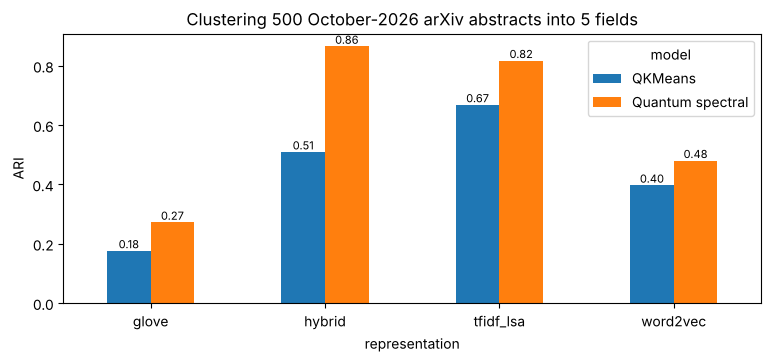

In [3]:
ax = table.plot.bar(figsize=(9, 3.5), rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_ylabel("ARI")
ax.set_title("Clustering 500 October-2026 arXiv abstracts into 5 fields")
plt.show()

## 2. Best pipeline + automatic labels for each cluster

In [4]:
best = QSpectralClustering(5, QuantumKernel("angle", 1), affinity="knn").fit(reps["hybrid"])
labels = cluster_labels(list(arxiv.X), best.labels_)
keywords = cluster_keywords(list(arxiv.X), best.labels_, 6)
for c in sorted(labels):
    members = arxiv.y[best.labels_ == c]
    field = arxiv.target_names[np.bincount(members).argmax()]
    purity = np.bincount(members).max() / len(members)
    print(f"cluster {c} ({len(members):3d} papers, {purity:.0%} {field:8s}) label: '{labels[c]}'  | {', '.join(keywords[c])}")
print(f"\nARI {adjusted_rand_score(arxiv.y, best.labels_):.3f}  NMI {normalized_mutual_info_score(arxiv.y, best.labels_):.3f}")

cluster 0 (103 papers, 89% q-bio   ) label: 'de novo'  | model, dynamics, across, neural, framework, analysis
cluster 1 ( 95 papers, 98% q-fin   ) label: 'limit order'  | market, risk, model, volatility, price, portfolio
cluster 2 (102 papers, 95% quant-ph) label: 'quantum states'  | quantum, states, classical, state, entanglement, error
cluster 3 (100 papers, 94% astro-ph) label: 'dark matter'  | galaxies, dark, stars, mass, data, stellar
cluster 4 (100 papers, 96% cs.CL   ) label: 'language models'  | models, language, across, model, reasoning, training

ARI 0.865  NMI 0.842


## 3. Word embeddings: classical vs quantum

In [5]:
w2v = Word2Vec(dim=100, epochs=15).fit(arxiv.X)
glove = GloVe(dim=50, epochs=30).fit(arxiv.X)
qwe = QuantumWordEmbeddings(n_qubits=4, epochs=2, min_count=5).fit(arxiv.X)
for word in ["quantum", "volatility", "galaxies", "language", "protein"]:
    print(f"\n{word}:")
    for name, model in [("Word2Vec", w2v), ("GloVe", glove), ("Quantum (4 qubits)", qwe)]:
        if (word in model) if hasattr(model, "__contains__") else (word in model.index_):
            print(f"  {name:19s}", ", ".join(w for w, _ in model.most_similar(word, 6)))


quantum:
  Word2Vec            computing, implementation, circuit, continuous-variable, fault-tolerant, hybrid
  GloVe               metrology, unassisted, eigensolver, bosonic, sample-based, sensors
  Quantum (4 qubits)  qubits, computation, computing, limitation, codes, provide

volatility:
  Word2Vec            prices, option, stochastic, futures, liquidity, trading
  GloVe               stochastic, signature, model, rough, captures, reproduces
  Quantum (4 qubits)  signature, model, claude, super, accuracy, mean

galaxies:
  Word2Vec            galactic, massive, formation, galaxy, star, radio
  GloVe               hoag-type, satellite, late-type, high-redshift, matter-deficient, sector
  Quantum (4 qubits)  cores, emitters, x-ray, dmdgs, mass, electronic

language:
  Word2Vec            llms, increasingly, medical, masked, pretrained, speech
  GloVe               large, natural, llms, lms, masked, autoregressive
  Quantum (4 qubits)  large, models, llms, european, remnant, long-c

## 4. Quantum NLP classifiers

### 4a. Grammar-aware DisCoCat on typed sentences (food vs IT)

In [6]:
sents, y_mc, plain = make_mc_dataset(130)
for s, lab in list(zip(sents, y_mc))[:4]:
    print(lab, s)
results = {}
dc = DisCoCatClassifier(epochs=60).fit(sents[:90], y_mc[:90])
results["DisCoCat (pregroup grammar)"] = dc.score(sents[90:], y_mc[90:])
results["Spiders (bag of words)"] = SpiderQNLPClassifier(n_qubits=2, min_count=1).fit(plain[:90], y_mc[:90]).score(plain[90:], y_mc[90:])
results["Word sequence"] = WordSequenceQNLPClassifier(3, 6, min_count=1).fit(plain[:90], y_mc[:90]).score(plain[90:], y_mc[90:])
pd.Series(results, name="test accuracy").round(3)

1 [('clever', 'adj'), ('programmer', 'n'), ('codes', 'iv')]
0 [('woman', 'n'), ('bakes', 'tv'), ('bread', 'n')]
1 [('man', 'n'), ('codes', 'iv')]
1 [('young', 'adj'), ('woman', 'n'), ('codes', 'iv')]


DisCoCat (pregroup grammar)    0.975
Spiders (bag of words)         1.000
Word sequence                  1.000
Name: test accuracy, dtype: float64

### 4b. Harder: field of an arXiv paper from its title (5 classes, chance = 20%)

In [7]:
titles = np.array(arxiv.meta["title"], dtype=object)
order = np.random.default_rng(0).permutation(len(titles))
tr, te = order[:400], order[400:]
acc = {}
acc["Spiders, 3 qubits"] = SpiderQNLPClassifier(n_qubits=3, epochs=30).fit(titles[tr], arxiv.y[tr]).score(titles[te], arxiv.y[te])
acc["Word sequence, 4 qubits"] = WordSequenceQNLPClassifier(4, 8, epochs=20).fit(titles[tr], arxiv.y[tr]).score(titles[te], arxiv.y[te])
pd.Series(acc, name="accuracy").round(3)

Spiders, 3 qubits          0.47
Word sequence, 4 qubits    0.26
Name: accuracy, dtype: float64